In [1]:
import numpy as np
import stim
from IPython.display import Markdown, display

from library.circuitry import Circuitry
from library.qubit_array import QubitArray
from library.steane_code.patch import SteaneCodePatch
from utils.fault_analysis import enumerate_faults

In [2]:
# Implementation assisted by Claude.AI (2026)

In [3]:
qubits: QubitArray = QubitArray(dimensions=(5,5))
circuitry = Circuitry(qubits, clifford=True)
steane = SteaneCodePatch(array=qubits, injection=None)

steane.append_cultivation(circuitry)

circuitry.annotate_detector("STN:CULT:X0", "STN:CULT:X1")
for mk in range(2, 7):
    circuitry.annotate_detector(f"STN:CULT:X{mk}")
for mk in range(2):
    circuitry.annotate_detector(f"STN:CULT:Z{mk}")

circuitry.detectors_report(open_boundaries=True)

display(Markdown(f"[Open in Crumble (Cultivation)]({circuitry.to_crumble_url()})"))

Detector statistics : 
> Measurement records : 9
> Number of detectors : 8 [postselected:0]
> Missing detectors : 0
> Gauge detectors : NONE


[Open in Crumble (Cultivation)](https://algassert.com/crumble.html#circuit=QUBIT_COORDS(0,_2)_0;QUBIT_COORDS(1,_0)_3;QUBIT_COORDS(1,_1)_4;QUBIT_COORDS(1,_2)_5;QUBIT_COORDS(2,_0)_8;QUBIT_COORDS(2,_1)_9;QUBIT_COORDS(2,_2)_12;QUBIT_COORDS(3,_0)_13;QUBIT_COORDS(3,_2)_14;QUBIT_COORDS(0.5,_0.5)_1;QUBIT_COORDS(0.5,_1.5)_2;QUBIT_COORDS(1.5,_0.5)_6;QUBIT_COORDS(1.5,_1.5)_7;QUBIT_COORDS(2.5,_0.5)_10;QUBIT_COORDS(2.5,_1.5)_11;RX_6_10_2_7_11_1;R_8_5;TICK;CX_11_14_6_3_10_13_2_0_7_9_1_4;TICK;TICK;TICK;CX_9_10_4_2_11_12;TICK;CX_9_11_6_4;TICK;CX_6_9;TICK;MX_6;TICK;RX_6;TICK;CX_6_9;TICK;CX_9_11_6_4;TICK;CX_9_10_4_2_11_12;TICK;TICK;TICK;CX_11_14_6_3_10_13_2_0_7_9_1_4;TICK;MX_6_10_2_7_11_1;M_8_5;TICK;DETECTOR_rec[-9]_rec[-8];DETECTOR_rec[-7];DETECTOR_rec[-6];DETECTOR_rec[-5];DETECTOR_rec[-4];DETECTOR_rec[-3];DETECTOR_rec[-2];DETECTOR_rec[-1])

In [4]:
# DATA = [0, 3, 4, 7, 10, 11, 12]
# SUPPORTS = list(circuitry.remap_qubits(support) for support in steane.stabilizers.values())
# clifford = circuitry.as_stim()
# clifford.diagram("timeline-svg")

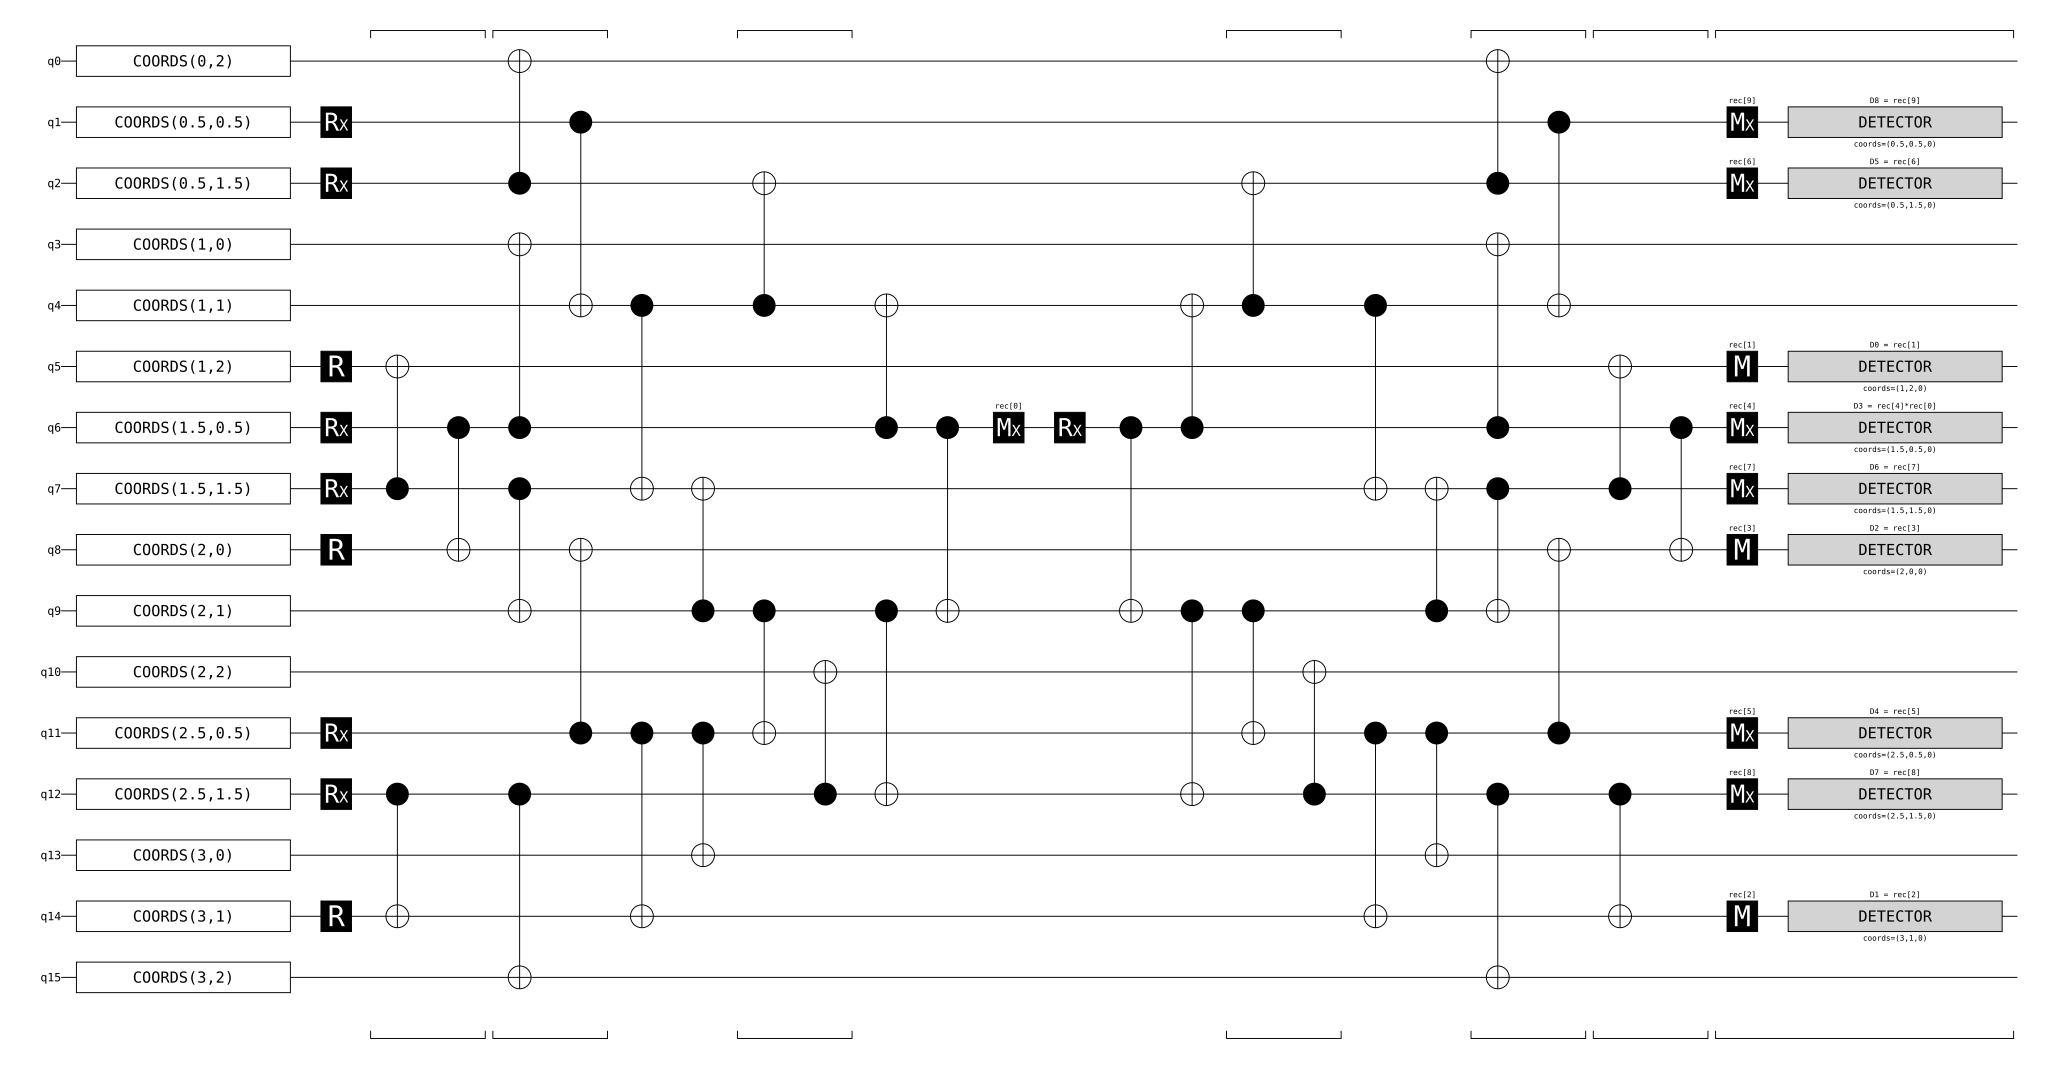

In [5]:
DATA = [0, 3, 4, 9, 10, 13, 14]
SUPPORTS = [ [9,10,13,14], [3,4,9,13], [0,4,9,10] ]
circuitry = stim.Circuit.from_file("../../assets/hirano-layout1-doublecheck-fixed.v1.stim")
clifford = circuitry
clifford.diagram("timeline-svg")

In [6]:
def flips_hxy(frame):
    _, zs = stim.PauliString(frame).to_numpy()
    return bool(zs[DATA].sum() % 2)

def detected_internally(flips):
    return np.frombuffer(flips, dtype=bool).any()

def detected_z_check(frame):
    xs, _ = stim.PauliString(frame).to_numpy()
    for support in SUPPORTS:
        if xs[support].sum() % 2 == 1:
            return True
    return False

def detected_x_check(frame):
    xs, zs = stim.PauliString(frame).to_numpy()

    for support in SUPPORTS:
        x, z = xs[support], zs[support]
        count_h = int(x.sum())
        if count_h == 0:
            if z.sum() % 2 == 1:
                return True
        elif count_h == 4:
            if (x & ~z).sum() % 2 == 1:
                return True
    return False

In [7]:
faults, outcomes = enumerate_faults(circuitry)
group_count = len(outcomes)

print(f"Fault count [k=1] : {len(faults)}")
print(f"Group count [k=1] : {group_count}")

Fault count [k=1] : 609
Group count [k=1] : 327


In [8]:
fault_count = sum(
    len(configurations) for (frame, flips), configurations in outcomes.items()
    if flips_hxy(frame) and not detected_internally(flips) and not detected_z_check(frame) and not detected_x_check(frame)
)
group_count = sum(
    1 for (frame, flips), configurations in outcomes.items()
    if flips_hxy(frame) and not detected_internally(flips) and not detected_z_check(frame) and not detected_x_check(frame)
)

print(f"Number of undetected Hxy-flips caused by single faults : {fault_count} [groups:{group_count}]")
for (frame, flips), configurations in outcomes.items():
    if not flips_hxy(frame) or detected_internally(flips) or detected_z_check(frame) or detected_x_check(frame):
        continue

    print(f"Frame [{len(configurations)}] : {frame}")

    print(type(configurations), repr(next(iter(configurations))))

    for op_idx, tk_idx, fault in configurations:
        pauli = "*".join(f"{p}{q}" for q, p in sorted(fault.items()))
        display(Markdown(f"[Open in Crumble (Cultivation {pauli}@T{tk_idx} : `{frame}`)]({circuitry.to_crumble_url(marks=[(op_idx, fault, 0)])})"))

Number of undetected Hxy-flips caused by single faults : 0 [groups:0]


In [9]:
faults, outcomes = enumerate_faults(circuitry, k=2)
group_count = len(outcomes)

print(f"Fault count [k=2] : {len(faults)}")
print(f"Group count [k=2] : {group_count}")

Fault count [k=2] : 609
Group count [k=2] : 34846


In [10]:
fault_count = sum(
    len(configurations) for (frame, flips), configurations in outcomes.items()
    if flips_hxy(frame) and not detected_internally(flips) and not detected_z_check(frame) and not detected_x_check(frame)
)
group_count = sum(
    1 for (frame, flips), configurations in outcomes.items()
    if flips_hxy(frame) and not detected_internally(flips) and not detected_z_check(frame) and not detected_x_check(frame)
)

print(f"Number of undetected Hxy-flips caused by double faults : {fault_count} [groups:{group_count}]")
for (frame, flips), configurations in outcomes.items():
    if not flips_hxy(frame) or detected_internally(flips) or detected_z_check(frame) or detected_x_check(frame):
        continue

    print(f"Frame [{len(configurations)}] : {frame}")
    for configuration in configurations:
        paulis = []
        marks = []
        for ft_idx in configuration:
            op_idx, tk_idx, fault = faults[ft_idx]
            paulis.append("*".join(f"{p}{q}" for q, p in sorted(fault.items())) + f"@T{tk_idx}")
            marks.append( (op_idx, fault, 0) )
        display(Markdown(f"[Open in Crumble (Cultivation {" + ".join(paulis)})]({circuitry.to_crumble_url()})"))

Number of undetected Hxy-flips caused by double faults : 0 [groups:0]
